# Identify lung-specific gene expression in each cell type
1. [Visualize QC statistics in lung and spleen samples](#section1)
2. [Rename cell types for simplicity](#section2)
3. [Identify marker genes for each cell type](#section3)
4. [cross-tissue DE analysis in each cell type](#section4)
5. [Examine the functions of lung or spleen DE genes](#section5)

In [ ]:
## Load package and the seurat object
library(Seurat)
library(data.table)
library(dplyr)
library(ggplot2)
library(plotly)
library(patchwork)
library(clusterProfiler)
library(org.Hs.eg.db)
library(enrichplot)
library(GOSemSim)
library(gridExtra)
library(slingshot)
source("../../code/make_plots.R")
options(repr.plot.width=14, repr.plot.height=10)

Attaching SeuratObject

Seurat v4 was just loaded with SeuratObject v5; disabling v5 assays and
validation routines, and ensuring assays work in strict v3/v4
compatibility mode


Attaching package: ‘dplyr’


The following objects are masked from ‘package:data.table’:

    between, first, last


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘plotly’


The following object is masked from ‘package:ggplot2’:

    last_plot


The following object is masked from ‘package:stats’:

    filter


The following object is masked from ‘package:graphics’:

    layout




clusterProfiler v4.6.2  For help: https://yulab-smu.top/biomedical-knowledge-mining-book/

If you use clusterProfiler in published research, please cite:
T Wu, E Hu, S Xu, M Chen, P Guo, Z Dai, T Feng, L Zhou, W Tang, L Zhan, X Fu, S Liu, X Bo, and G Yu. clusterProfiler 4.0: A universal enr

In [ ]:
dataDIR <- "../../output/output_dir/remove_dup/"
pal_atac <- readRDS("~/projects/Lung_scMultiomics_paper/data/color_codes.RDS")
pal_rna <- pal_atac
names(pal_rna)[3:4] <- c("memCD4_T", "naiCD4_T")


In [ ]:
immune.combined<-readRDS(paste0(dataDIR, "lungs_spleens_integrated.RDS"))
immune.combined@active.assay<-"RNA"
immune.combined

<a id='section4'></a>

## 4 Cross-tissue DE analysis in each cell type 

We performed differential gene expression between tissue with pseudo-bulk samples using DESeq2 (v1.38.3) (Love, Huber, and Anders, 2014). The test was done on the RNA count matrix
aggregated by donor, tissue and cell types using Seurat::AggregateExpression. We also adjusted
for covariates including batch, ethnicity, age, and sex.

In [ ]:
lungs <- readRDS(paste0(dataDIR, "lungs_integrated.RDS"))
spleens <- readRDS(paste0(dataDIR, "spleens_integrated.RDS"))

In [24]:
merged_meta <- immune.combined@meta.data
ct_dict <- 
    data.frame(orig = unique(merged_meta$majority_voting),
               label = c("Memory_B",
                         "NK",
                         "CD4_T",
                         "CD8_T",
                         "Th17",
                         "Other",
                         "Other",
                         "Naive_B",
                         "Treg",
                         "Other",
                         "NK",
                         "Other")) 

merged <- 
    data.frame(
        Barcode = unlist(lapply(rownames(merged_meta), function(i){strsplit(i, '_')[[1]][1]})), 
        Tissue = merged_meta$tissue.ident,
        CellType = ct_dict$label[match(merged_meta$majority_voting, ct_dict$orig)])

separate <- rbind(
     data.frame(
        Barcode = rownames(lungs@meta.data),
        Tissue = rep("lungs", nrow(lungs@meta.data)),
        CellType = ct_dict$label[match(lungs@meta.data$majority_voting, ct_dict$orig)]),
     data.frame(
        Barcode = rownames(spleens@meta.data),
        Tissue = rep("spleens", nrow(spleens@meta.data)),
        CellType = ct_dict$label[match(spleens@meta.data$majority_voting, ct_dict$orig)])
    )

In [32]:
lungs$SingleTissue <- 
    factor(lungs$majority_voting,
           labels = c("NK",
                      "NK",
                      "Other",
                      "Other",
                      "Memory_B",
                      "Naive_B",
                      "Other",
                      "Treg",
                      "naiCD4_T",
                      "memCD4_T",
                      "CD8_T"))
spleens$SingleTissue <- 
    factor(spleens$majority_voting,
           labels = c("NK",
                      "NK",
                      "Other",
                      "Memory_B",
                      "Naive_B",
                      "naiCD4_T",
                      "CD8_T"))

In [41]:
immune.combined$majority_voting <- labels$majority_voting
immune.combined$CellType <- immune.combined$majority_voting
immune.combined$CellType <-
    factor(immune.combined$CellType,
           levels = levels(factor(immune.combined$majority_voting)),
           label = c("Memory_B",
                         "NK",
                         "NK",
                         "Other",
                         "Other",
                         "Memory_B",
                         "Naive_B",
                         "Treg",
                         "naiCD4_T",
                         "memCD4_T",
                         "CD8_T"))

In [40]:
lungs_labels <- fread("../../output/lungs_integrated_noDoublets.csv")
lungs@meta.data$majority_voting <- lungs_labels$majority_voting[match(rownames(lungs@meta.data), lungs_labels$V1)]
spleens_labels <- fread("../../output/spleens_integrated_noDoublets.csv")
spleens@meta.data$majority_voting <- spleens_labels$majority_voting[match(rownames(spleens@meta.data), spleens_labels$V1)]
labels <- fread("../../output/predicted_labels_integrated_removeDup.txt")

In [ ]:
library("SeuratDisk")
DefaultAssay(spleens)<-"RNA"
SaveH5Seurat(spleens, 
             filename = "spleens_integrated.h5Seurat")
Convert("spleens_integrated.h5Seurat", dest = "h5ad")

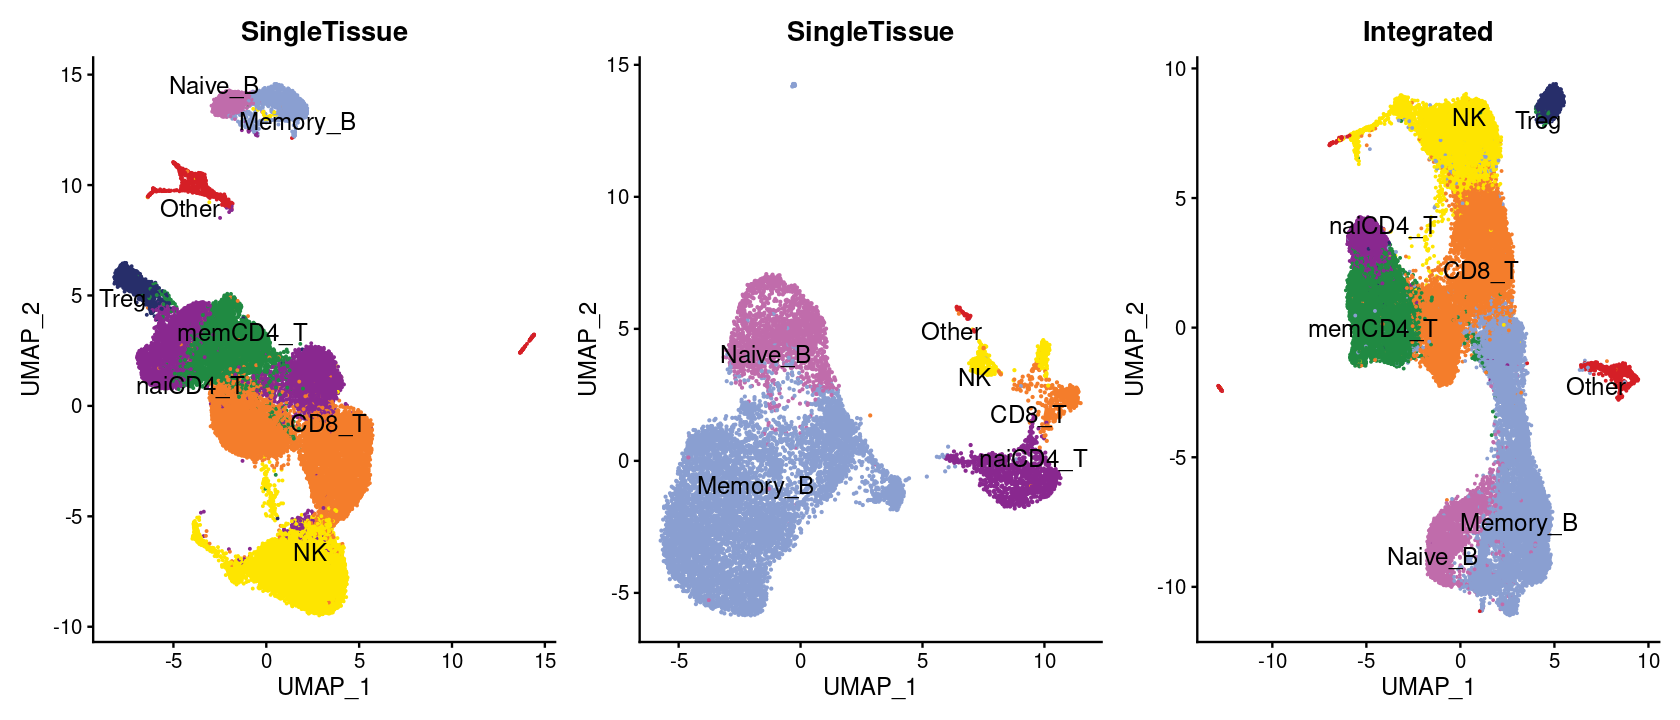

In [62]:
options(repr.plot.width=14, repr.plot.height=6)
p1 <- DimPlot(lungs, reduction = "umap", group.by = "SingleTissue", 
              cols = pal_rna, label.size = 5, label=TRUE, repel = TRUE)
p2 <- DimPlot(spleens, reduction = "umap", group.by = "SingleTissue",
              cols = pal_rna, label.size = 5, label=TRUE, repel = TRUE)
p3 <- DimPlot(immune.combined, reduction = "umap", group.by = "CellType", 
              cols = pal_rna, label.size = 5, label = TRUE, repel = TRUE) + ggtitle("Integrated")
p1 + p2 + p3 & NoLegend() & theme(plot.title = element_text(hjust = 0.5))

In [67]:
jaccard <- function(a, b) {
    intersection = sum(a == b, na.rm = TRUE)
    union = length(a) + length(b) - intersection
    return (c(intersection, union, intersection/union))
}

labels_tbl <- rbind(
    data.frame(SingleTissue = lungs@meta.data$SingleTissue,
                         CellBarcode = rownames(lungs@meta.data)),
    data.frame(SingleTissue = spleens@meta.data$SingleTissue,
                         CellBarcode = rownames(spleens@meta.data)))
labels_tbl$Integrated <- immune.combined$CellType[match(labels_tbl$CellBarcode, 
                                                        rownames(immune.combined@meta.data))]

In [86]:
jaccard(labels_tbl$SingleTissue, labels_tbl$Integrated)


[1] 3.844400e+04 5.319600e+04 7.226859e-01

In [85]:
labels_tbl <- labels_tbl %>% filter()
jaccard(labels_tbl$SingleTissue, labels_tbl$Integrated)
t(sapply(unique(as.character(labels_tbl$SingleTissue)), function(i) {
    df <- labels_tbl %>% filter(SingleTissue == i)
    return(jaccard(df$SingleTissue, df$Integrated))
}))

[1] 3.844400e+04 5.319600e+04 7.226859e-01

NK,7514,8050,0.9334161
naiCD4_T,2082,12956,0.1606977
CD8_T,10607,11729,0.9043397
memCD4_T,4486,5230,0.8577438
Naive_B,2855,3351,0.8519845
Treg,1009,1135,0.8889868
Memory_B,9001,9767,0.9215726
Other,890,978,0.9100204


In [ ]:
orig_labels <- fread("../../output/rna_metadata.txt")
head(orig_labels)

immune.combined$PriorClusters <- 
    orig_labels$`integrated_snn_res.0.5`[match(rownames(immune.combined@meta.data), orig_labels$X)]
table(immune.combined$PriorClusters)

In [ ]:
labels <- fread("../../output/predicted_labels_integrated_removeDup.txt")
immune.combined$majority_voting <- labels$majority_voting


immune.combined$CellType <- immune.combined$majority_voting
immune.combined$CellType <-
    factor(immune.combined$CellType,
           levels = levels(factor(immune.combined$majority_voting)),
           label = c("Memory_B",
                         "NK",
                         "NK",
                         "Other",
                         "Other",
                         "Memory_B",
                         "Naive_B",
                         "Treg",
                         "naiCD4_T",
                         "memCD4_T",
                         "CD8_T"))

In [15]:
table(immune.combined$CellType, immune.combined$tissue.ident)

          
           lungs spleens
  Memory_B  4180    8052
  NK        7283     462
  Other      874      23
  Naive_B   1119    2095
  Treg      1082      45
  naiCD4_T  1928     237
  memCD4_T  6402     648
  CD8_T    11030     360

In [8]:
platte = c("#D51F26","#272E6A", "#208A42", "#89288F", "#F47D2B", "#FEE500", "#8A9FD1", "#C06CAB")
ct_order <-
  c(
  "Naive_B",
  "Memory_B",
  "NK",
  "CD8_T",
  "CD4_T",
  "Th17",
  "Treg",
  "Other"
)

An object of class Seurat 
321136 features across 53647 samples within 4 assays 
Active assay: RNA (36601 features, 0 variable features)
 2 layers present: counts, data
 3 other assays present: ATAC, integrated, peaks
 3 dimensional reductions calculated: pca, umap, lsi

<a id='section1'></a>
## 1 Visualize QC statistics in lung and spleen samples

In [ ]:
lung<-readRDS("AGG_lungs/all_lungs_integrated_multi.rds")

p1 <- VlnPlot(lung, features = c("nCount_ATAC"),#, "nCount_RNA","percent.mt"), ncol = 3,
  log = TRUE, pt.size = 0) + NoLegend() + 
    theme(axis.text.y = element_text(size = 15),
          axis.title.x = element_blank(),
          axis.text.x = element_blank()) 
p2 <- VlnPlot(lung, features = c("nCount_RNA"), 
  log = TRUE, pt.size = 0) + NoLegend() + 
    theme(axis.text.y = element_text(size = 15),
          axis.title.x = element_blank(),
          axis.text.x = element_blank()) 
p3 <- VlnPlot(lung, features = c("percent.mt"), 
  log = TRUE, pt.size = 0) + NoLegend() + 
    theme(axis.text.y = element_text(size = 15),
          axis.title.x = element_blank(),
          axis.text.x = element_blank()) 

#ggsave(p1|p2|p3, filename = "aggr_lung_statistics.pdf", width = 10, height = 4)

In [4]:
spleen<-readRDS("AGG_spleens/all_spleens_integrated_multi.rds")

p1 <- VlnPlot(lung, features = c("nCount_ATAC"),#, "nCount_RNA","percent.mt"), ncol = 3,
  log = TRUE, pt.size = 0) + NoLegend() + 
    theme(axis.text.y = element_text(size = 15),
          axis.title.x = element_blank(),
          axis.text.x = element_blank()) 
p2 <- VlnPlot(lung, features = c("nCount_RNA"), 
  log = TRUE, pt.size = 0) + NoLegend() + 
    theme(axis.text.y = element_text(size = 15),
          axis.title.x = element_blank(),
          axis.text.x = element_blank()) 
p3 <- VlnPlot(lung, features = c("percent.mt"), 
  log = TRUE, pt.size = 0) + NoLegend() + 
    theme(axis.text.y = element_text(size = 15),
          axis.title.x = element_blank(),
          axis.text.x = element_blank()) 

#ggsave(p1|p2|p3, filename = "aggr_spleen_statistics.pdf", width = 10, height = 4)

<a id='section2'></a>

## 2 Rename cell types for simplicity

In [7]:
immune.combined$CellType <- factor(
    immune.combined$CellType,
    levels = 
            c("Other", "Treg", "memCD4_T", "naiCD4_T",
              "CD8_T", "NK", "Memory_B", "Naive_B"))

In [11]:
table(immune.combined$CellType)


   Other     Treg memCD4_T naiCD4_T    CD8_T       NK Memory_B  Naive_B 
     897     1127     7050     2165    11390     7745    12232     3214 

In [ ]:
## UMAP visualization for integrated dataset colored by tissue, batch, cell type
p1 <- 
DimPlot(immune.combined, reduction = "pca", 
              group.by = "tissue.ident", 
              cols = platte, 
              #split.by = "tissue.ident", 
              label = FALSE, 
              repel = TRUE) +
    theme(legend.text = element_text(size = 18))
p2 <- 
DimPlot(immune.combined, reduction = "pca", 
              group.by = "batch", 
              cols = platte, 
              #split.by = "tissue.ident", 
              label = FALSE, 
              repel = TRUE) +
    theme(legend.text = element_text(size = 18))
p3 <- 
DimPlot(immune.combined, reduction = "pca", 
              group.by = "CellType", 
              cols = platte, 
              #split.by = "tissue.ident", 
              label = FALSE, 
              repel = TRUE) +
    theme(legend.text = element_text(size = 18))
p1 + p2 + p3

### Filtering out cluster 4 with high MT gene expression

In [ ]:
orig_labels <- fread("../../output/rna_metadata.txt")
head(orig_labels)

immune.combined$PriorClusters <- 
    orig_labels$`integrated_snn_res.0.5`[match(rownames(immune.combined@meta.data), orig_labels$X)]
table(immune.combined$PriorClusters)

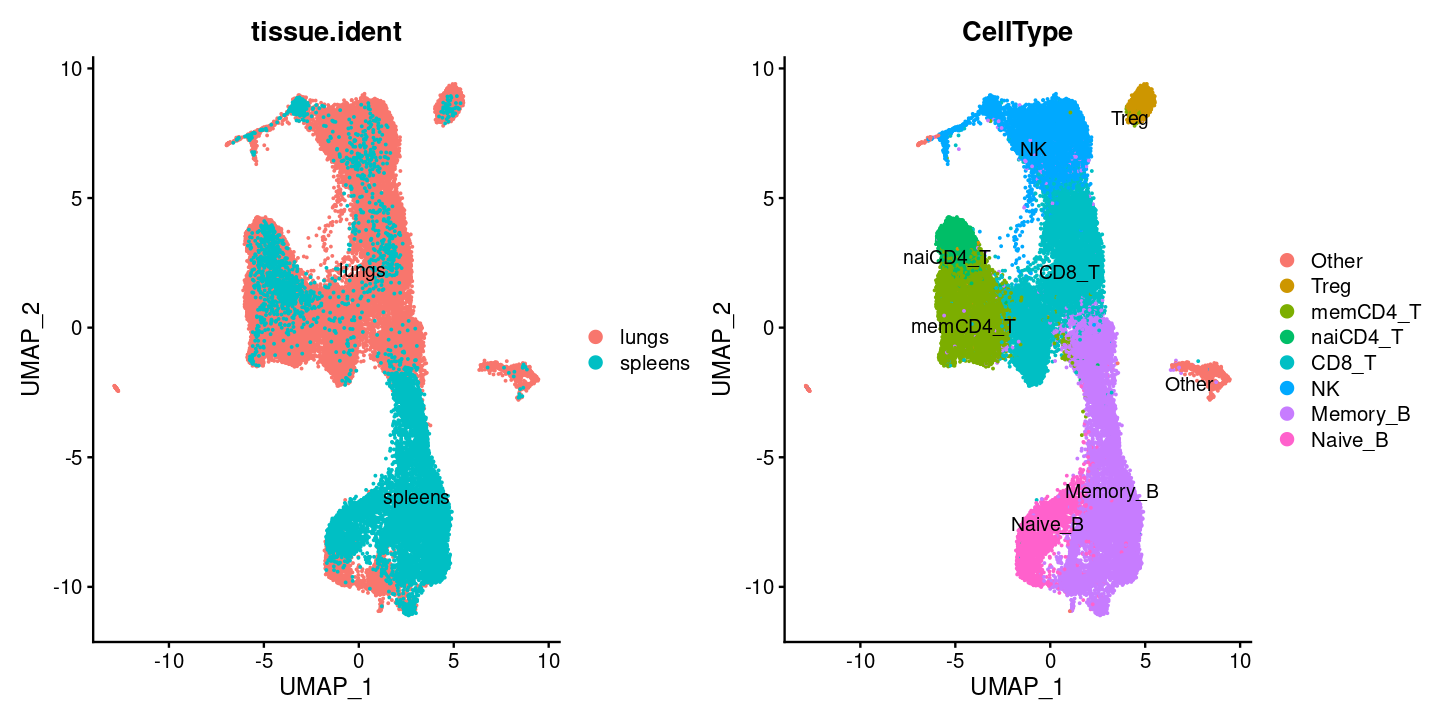

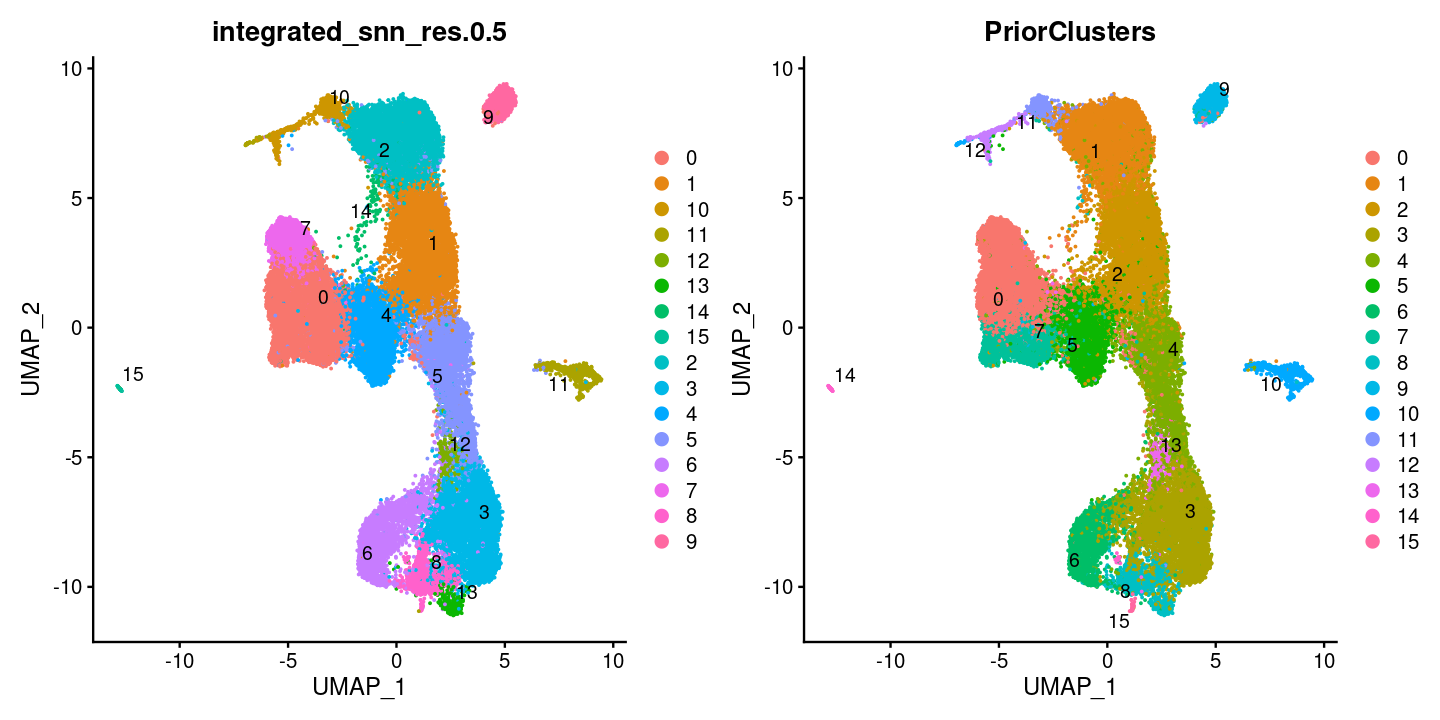

In [67]:
p1 <- DimPlot(immune.combined, reduction = "umap", group.by = "tissue.ident", label=TRUE, repel = TRUE)
p2 <- DimPlot(immune.combined, reduction = "umap", group.by = "integrated_snn_res.0.5", label = TRUE,
    repel = TRUE)
p3 <- DimPlot(immune.combined, reduction = "umap", group.by = "PriorClusters", label = TRUE,
    repel = TRUE)
p4 <- DimPlot(immune.combined, reduction = "umap", group.by = "CellType", label = TRUE,
    repel = TRUE)
p1 + p4
p2 + p3

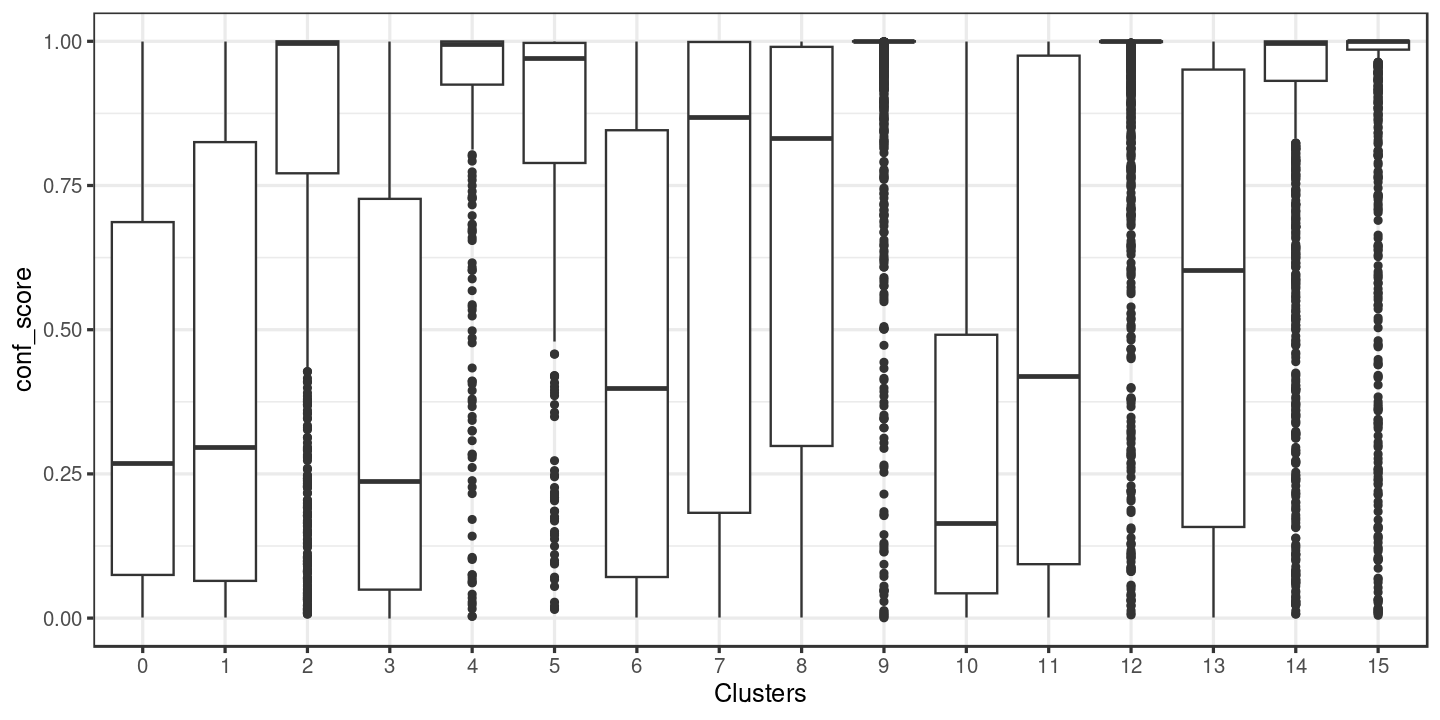

In [50]:
ggplot(labels, 
       aes(x = factor(over_clustering),
           y = conf_score)) + 
geom_boxplot() + xlab("Clusters") + 
theme_bw(base_size = 15)

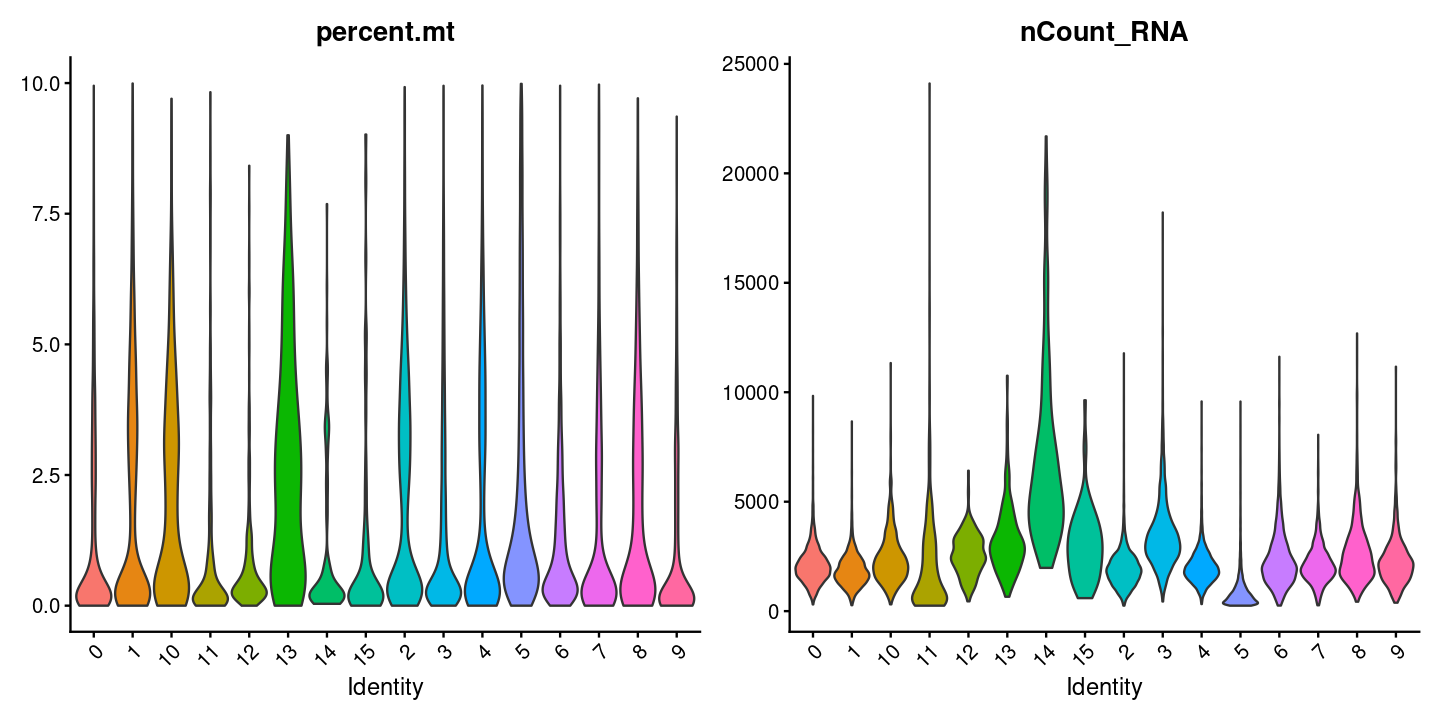

In [46]:
p <-VlnPlot(immune.combined, features = c("percent.mt", "nCount_RNA"), 
            #split.by = "tissue.ident",
            group.by = "integrated_snn_res.0.5", pt.size = 0)
p

In [10]:
immune.combined <- subset(immune.combined, PriorClusters != "4" | tissue.ident == "spleens")

In [11]:
immune.combined

An object of class Seurat 
321146 features across 42863 samples within 4 assays 
Active assay: RNA (36601 features, 0 variable features)
 2 layers present: counts, data
 3 other assays present: ATAC, integrated, peaks
 2 dimensional reductions calculated: pca, umap

In [12]:
saveRDS(immune.combined, "../../output/output_dir/remove_dup/lungs_spleens_integrated_sub.RDS")

<a id='section3'></a>

## 3 Identify marker genes for each cell type

In [ ]:
## differential expression analysis across cell types with the Wilcoxon rank sum test

immune.markers <- FindAllMarkers(immune.combined,
                                 group.by = immune.combined$CellType,
                                 only.pos = TRUE)
immune.markers %>%
    group_by(cluster) %>%
    dplyr::filter(avg_log2FC > 1)

immune.markers %>%
    group_by(cluster) %>%
    dplyr::filter(p_val_adj < 0.001) %>%
    arrange(desc(avg_log2FC)) %>%
    slice_head(n = 5) %>%
    ungroup() -> top5

### Dotplots for the expression of known marker genes across immune cells

In [26]:
markerGenes <- c(
    "CD69","IGHD", 
    "IL4R", "MS4A1",
      "BANK1", 
      "GNLY", "NKG7",
      "CD8B", "ITGA1", "GZMK",
      "LEF1", "TCF7", "IL7R",
      "CXCR6", "RGS1", "CCR7",
      "CTLA4", "IL2RA", "FOXP3")

In [84]:
#Idents(immune.combined) <- immune.combined$CellType
p2 <-
    DotPlot(subset(immune.combined, subset= CellType != "Other"),
        features = markerGenes) + 
    RotatedAxis() + xlab("") + ylab("") 
   

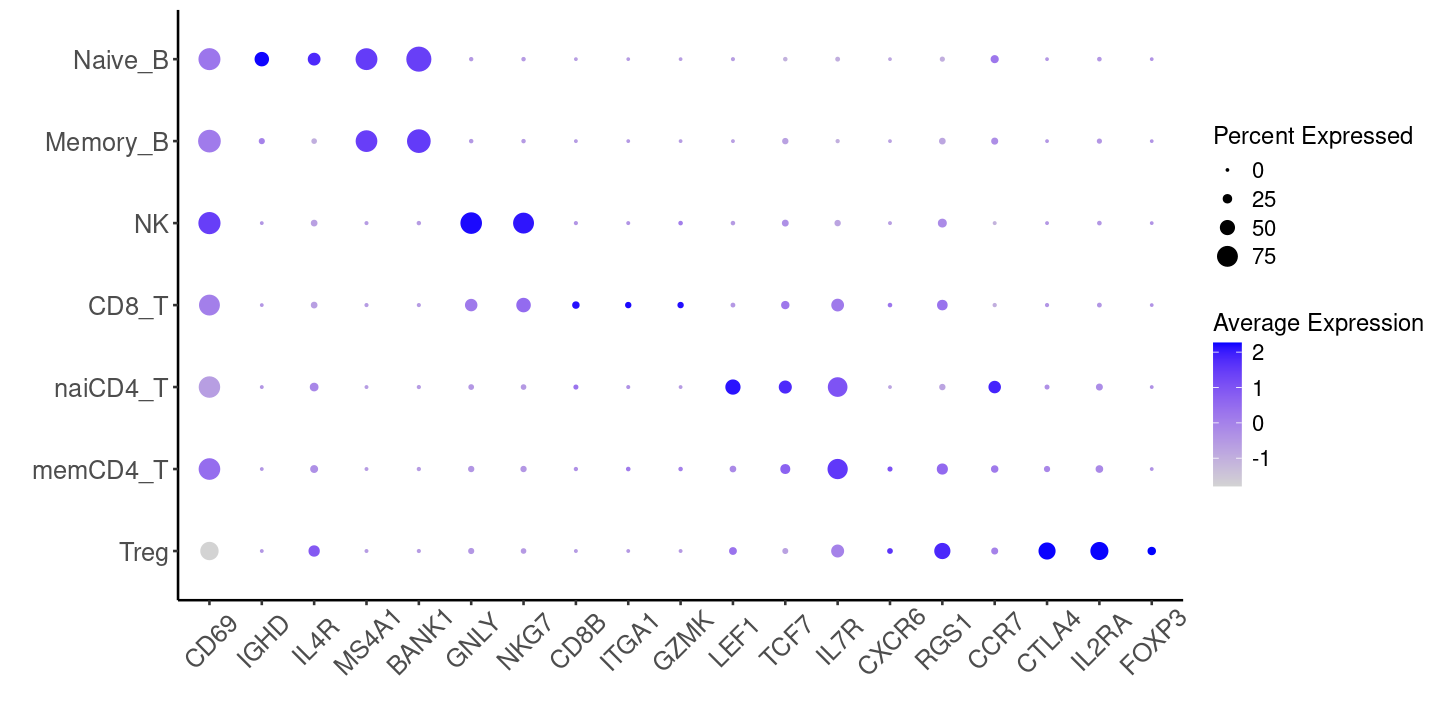

In [85]:
options(repr.plot.width=12, repr.plot.height= 6)
p2 + theme_classic(base_size = 12) + 
    theme(axis.text.x = element_text(size = 15, angle = 45, vjust=0.6),
          axis.text.y = element_text(size = 15),
          legend.title = element_text(size = 14),
          legend.text = element_text(size = 13))

### Dotplot split by tissue

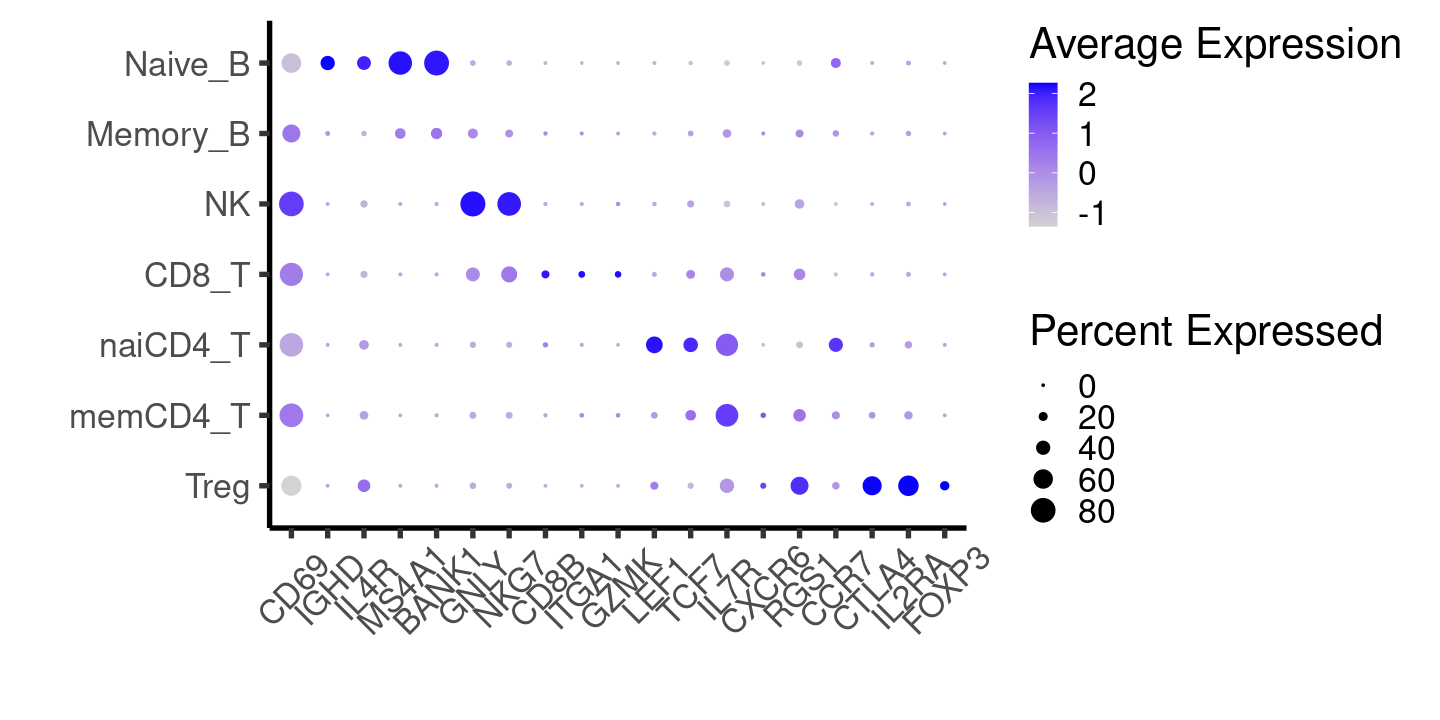

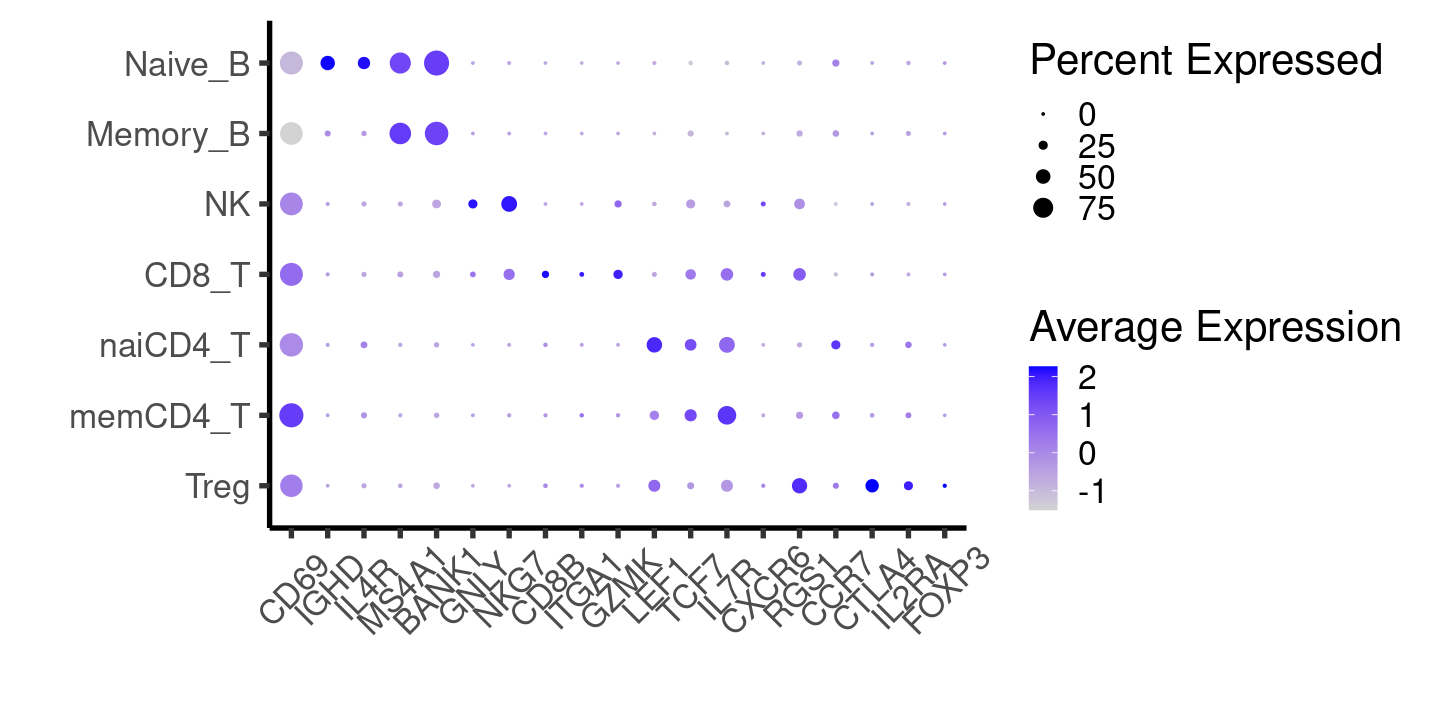

In [29]:
options(repr.plot.width=12, repr.plot.height= 6)
DotPlot(subset(immune.combined, CellType != "Other" & tissue.ident == "lungs"), 
        features = markerGenes) + 
        RotatedAxis() + xlab("") + ylab("") + 
theme_classic(base_size = 25) + 
theme(axis.text.x = element_text(angle = 45, vjust=0.6))

DotPlot(subset(immune.combined, CellType != "Other" & tissue.ident == "spleens"), 
        features = markerGenes) + 
        RotatedAxis() + xlab("") + ylab("") + 
theme_classic(base_size = 25) + 
theme(axis.text.x = element_text(angle = 45, vjust=0.6))

### Transferring to ATAC-seq labels 

In [50]:
atacmeta <- readRDS("../../output/atac_meta.RDS")
colnames(atacmeta)

[1] "Sample"             "nMultiFrags"        "nMonoFrags"        
 [4] "nFrags"             "nDiFrags"           "TSSEnrichment"     
 [7] "ReadsInTSS"         "ReadsInPromoter"    "ReadsInBlacklist"  
[10] "PromoterRatio"      "PassQC"             "NucleosomeRatio"   
[13] "DoubletScore"       "DoubletEnrichment"  "BlacklistRatio"    
[16] "Clusters"           "predictedCell_Un"   "predictedGroup_Un" 
[19] "predictedScore_Un"  "CellType"           "majority_voting"   
[22] "Tissue"             "Status"             "Batch"             
[25] "Sex"                "Age"                "Race"              
[28] "CellGroup"          "ReadsInPeaks"       "FRIP"              
[31] "CellGroup2"         "CellGroup3"         "PredCellType"      
[34] "partial"            "LabelTransfer"      "MajorityVote"      
[37] "predictedCell2_Un"  "predictedGroup2_Un" "predictedScore2_Un"

In [51]:
rnameta <- immune.combined@meta.data
rnameta$core_ID <- factor(rnameta$full.ident, 
                          labels = c(paste0("SMO", "-", c(2,3,5,7,8,9)),
                                     paste0("SMO", "-", c(1, 4, 10))))
rnameta$CellBarcode <-paste(rnameta$core_ID, gsub("-", "_", rownames(rnameta)), sep = "#")
rnameta$CellBarcode <- unlist(lapply(rnameta$CellBarcode, function(i) {strsplit(i, "_")[[1]][1]}))
atacmeta <- 
  data.frame(atacmeta) %>%
    mutate(CellBarcode = unlist(lapply(rownames(atacmeta), function(i) {paste(strsplit(i, "-")[[1]][1:2], collapse = "-")})))
atacmeta$FilteredCellType <- rnameta$CellType[match(atacmeta$CellBarcode, rnameta$CellBarcode)] #seurat_clusters


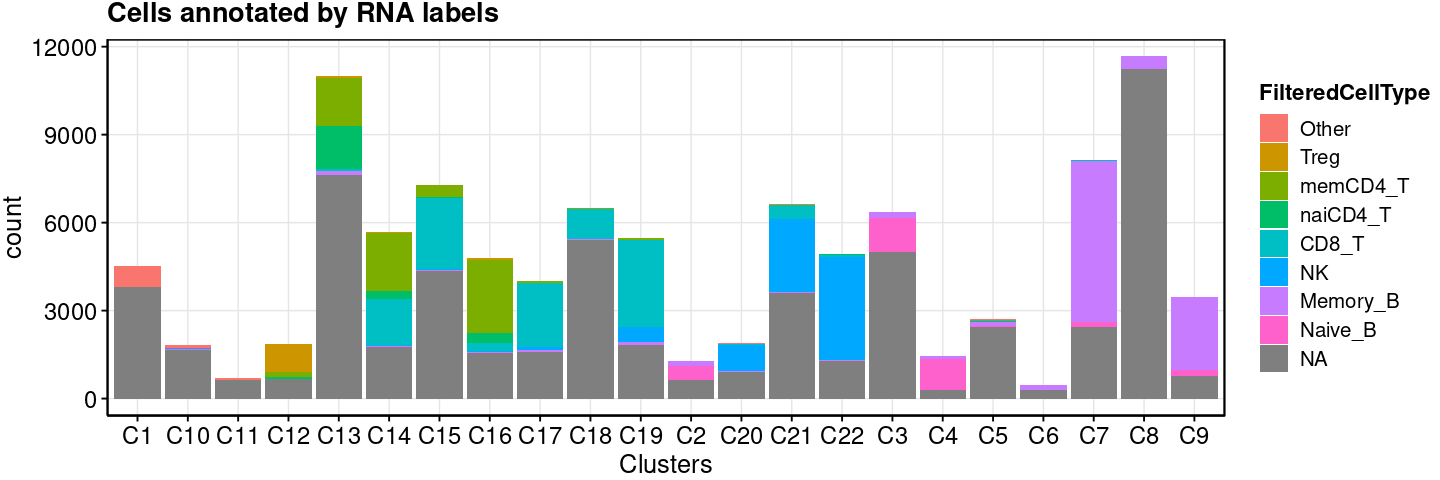

In [24]:
options(repr.plot.width=12, repr.plot.height= 4)
p4 <-   
ggplot(atacmeta,
       aes(x = Clusters,
           fill = FilteredCellType)) + 
  geom_bar() + 
  #theme_classic(base_size = 12) + 
  ggtitle("Cells annotated by RNA labels") + 
  theme_pub(base_size = 14)

p4

In [52]:
table(atacmeta$FilteredCellType)


   Other     Treg memCD4_T naiCD4_T    CD8_T       NK Memory_B  Naive_B 
     892     1116     6970     2142    11145     7674     9765     3159 

In [53]:
st_majority <- unlist(lapply(unique(atacmeta$Clusters), function(i) {
  ct <- atacmeta$FilteredCellType[atacmeta$Clusters == i]
  return(names(which.max(table(ct[!is.na(ct)]))))
}))

labels_tbl <-
    data.frame(Clusters = unique(atacmeta$Clusters),
           MajorityVoting = st_majority)

In [54]:
labels_tbl <-
    left_join(labels_tbl,
              unique(atacmeta[, c("Clusters", "PredCellType")]))
labels_tbl$RNALabels <- labels_tbl$PredCellType
labels_tbl$RNALabels[labels_tbl$Clusters == "C16"] <- "memCD4_T"

Joining with `by = join_by(Clusters)`


In [55]:
atacmeta$RNALabels <- atacmeta$Clusters
atacmeta$RNALabels <- 
    factor(atacmeta$Clusters, 
           levels = labels_tbl$Clusters,
           labels = labels_tbl$RNALabels)


In [56]:
saveRDS(atacmeta, "../output/")


 Memory_B     Other   Naive_B     CD8_T        NK     CD4_T      Treg  memCD4_T 
    26374      7011      9063     23195     13365     10969      1857      4776 
CD8/CD4_T 
     5667 

<a id='section4'></a>

## 4 Cross-tissue DE analysis in each cell type 

We performed differential gene expression between tissue with pseudo-bulk samples using DESeq2 (v1.38.3) (Love, Huber, and Anders, 2014). The test was done on the RNA count matrix
aggregated by donor, tissue and cell types using Seurat::AggregateExpression. We also adjusted
for covariates including batch, ethnicity, age, and sex.

In [49]:
head(immune.combined@meta.data)

,orig.ident,nCount_RNA,nFeature_RNA,percent.mt,nCount_ATAC,nFeature_ATAC,integrated_snn_res.0.5,seurat_clusters,immune_low,lung_atlas,tissue.ident,full.ident,nCount_peaks,nFeature_peaks,majority_voting,merged,CellType
,<chr>,<dbl>,<int>,<dbl>,<dbl>,<int>,<fct>,<fct>,<chr>,<chr>,<chr>,<chr>,<dbl>,<int>,<chr>,<chr>,<chr>
AAACAGCCAACAACAA-2_1,2,4891,2351,1.819669,20272,8234,8,8,Memory B cells,B cells,lungs,lungs_2,11791,8456,Memory B cells,Memory B cells,Memory_B
AAACAGCCACAGCCTG-2_1,2,2106,1225,4.415954,7866,3694,1,1,CD16+ NK cells,NK cells,lungs,lungs_2,4511,3829,CD16+ NK cells,CD16+ NK cells,NK
AAACAGCCAGGATGGC-2_1,2,2503,1303,3.995206,8074,3733,0,0,Tcm/Naive helper T cells,CD4 T cells,lungs,lungs_2,4668,3890,Tcm/Naive helper T cells,T cells,CD4_T
AAACAGCCATCAGTAT-2_1,2,3573,1591,4.114190,19628,8126,0,0,Tcm/Naive helper T cells,CD4 T cells,lungs,lungs_2,11343,8194,Tcm/Naive helper T cells,T cells,CD4_T
AAACAGCCATGAAGTA-2_1,2,6324,2584,1.391524,856,451,2,2,Tem/Trm cytotoxic T cells,CD8 T cells,lungs,lungs_2,485,478,Tem/Trm cytotoxic T cells,T cells,CD8_T
AAACAGCCATTAAACC-2_1,2,3075,1388,4.715447,10015,4639,7,7,Type 17 helper T cells,CD4 T cells,lungs,lungs_2,5740,4795,Type 17 helper T cells,T cells,Th17


In [50]:
head(sample_cov[, 1:8])

ROBI,cells,library_id,submission_date,Age,Sex,Race,Asthmatic status
<int>,<chr>,<chr>,<int>,<int>,<chr>,<chr>,<chr>
554,Spleen,SMO-1,8092022,46,M,White: non specified,non
554,Lung,SMO-2,8092022,46,M,White: non specified,non
706,Lung,SMO-3,8092022,57,F,Black or African American,non
635,Spleen,SMO-4,10102022,57,F,White: non specified,non
635,Lung,SMO-5,10102022,57,F,White: non specified,non
597,Lung,SMO-7,10102022,30,M,Black or African American,non


In [51]:
## Prepare aggregated RNA count matrix
sample_cov <- fread("../data/sample_covariates.txt")
colnames(sample_cov)[3] <- "library_id"

# match by sample ID
metadata <- data.frame(
    library_id = c(paste("SMO", c(2,3,5,7,8,9), sep = "-"),
                   paste("SMO", c(1,4,10), sep = "-")),
    full.ident = c(paste("lungs", 1:6, sep = "_"),
                   paste("spleens", 1:3, sep = "_")))

immune.combined@meta.data$library_id <- left_join(immune.combined@meta.data, metadata) %>% pull(library_id)
immune.combined@meta.data$CellGroup <- paste(immune.combined$library_id, immune.combined$CellType, sep = "-")
immune.combined@meta.data <- left_join(immune.combined@meta.data, sample_cov[, 1:8])
immune.combined@meta.data$Batch <- left_join(immune.combined@meta.data, sample_cov) %>% pull(submission_date)
immune.combined@meta.data$Donor <- left_join(immune.combined@meta.data, sample_cov) %>% pull(ROBI)
immune.combined$CellTypeTissue <- paste(immune.combined$CellType, immune.combined$tissue.ident, sep = "_")
Idents(immune.combined) <- "CellTypeTissue"

Joining with `by = join_by(full.ident)`
Joining with `by = join_by(library_id)`
Joining with `by = join_by(library_id, ROBI, cells, submission_date, Age, Sex,
Race, `Asthmatic status`)`
Joining with `by = join_by(library_id, ROBI, cells, submission_date, Age, Sex,
Race, `Asthmatic status`)`


In [115]:
pseudo_rna <- AggregateExpression(immune.combined, return.seurat = T, assays = "RNA", 
                                group.by = c("full.ident", "CellType"))

Centering and scaling data matrix



In [117]:
pseudo_rna@meta.data$full.ident <-
    unlist(lapply(rownames(pseudo_rna@meta.data), function(i) {paste(strsplit(i, "_")[[1]][1:2], collapse="-")}))

In [119]:
head(pseudo_rna@meta.data)

,orig.ident,nCount_RNA,nFeature_RNA,full.ident
,<fct>,<dbl>,<int>,<chr>
lungs_1_CD4_T,lungs,9860000,21081,lungs-1
lungs_1_CD8_T,lungs,11200000,21131,lungs-1
lungs_1_Memory_B,lungs,5150000,18789,lungs-1
lungs_1_Naive_B,lungs,4060000,16727,lungs-1
lungs_1_NK,lungs,10560000,20922,lungs-1
lungs_1_Other,lungs,3200000,19451,lungs-1


In [129]:
pseudo_rna@meta.data <- 
    left_join(pseudo_rna@meta.data, 
              metadata %>% 
                  mutate(full.ident = gsub("_", "-", full.ident)) %>% 
                  dplyr::select(full.ident, library_id, submission_date, Age, Sex, Race, Batch, Donor, `Asthmatic status`) %>%
                  distinct())


Joining with `by = join_by(full.ident, library_id, submission_date, Age, Sex,
Race, Batch, Donor, `Asthmatic status`)`


In [133]:
head(pseudo_rna@meta.data)

,orig.ident,nCount_RNA,nFeature_RNA,full.ident,library_id,submission_date,Age,Sex,Race,Batch,Donor,Asthmatic status
,<fct>,<dbl>,<int>,<chr>,<chr>,<int>,<int>,<chr>,<chr>,<int>,<int>,<chr>
1,lungs,9860000,21081,lungs-1,SMO-2,8092022,46,M,White: non specified,8092022,554,non
2,lungs,9860000,21081,lungs-1,SMO-2,8092022,46,M,White: non specified,8092022,554,non
3,lungs,9860000,21081,lungs-1,SMO-2,8092022,46,M,White: non specified,8092022,554,non
4,lungs,9860000,21081,lungs-1,SMO-2,8092022,46,M,White: non specified,8092022,554,non
5,lungs,9860000,21081,lungs-1,SMO-2,8092022,46,M,White: non specified,8092022,554,non
6,lungs,9860000,21081,lungs-1,SMO-2,8092022,46,M,White: non specified,8092022,554,non


In [127]:
## Group cells into pseudobulk by donor, tissue and cell types
pseudo_rna <- AggregateExpression(immune.combined, return.seurat = T, 
                                  assays = "RNA", slot = "counts",
                                  group.by = c("full.ident", "CellType"))
pseudo_rna@meta.data$full.ident <-
    unlist(lapply(rownames(pseudo_rna@meta.data), function(i) {paste(strsplit(i, "_")[[1]][1:2], collapse="-")}))

metadata <- immune.combined@meta.data %>%
                mutate(full.ident = gsub("_", "-", full.ident))

pseudo_rna@meta.data <- 
    left_join(pseudo_rna@meta.data, 
              metadata %>% 
                  mutate(full.ident = gsub("_", "-", full.ident)) %>% 
                  dplyr::select(full.ident, library_id, submission_date, Age, Sex, Race, Batch, Donor, `Asthmatic status`) %>%
                  distinct())

# Add rownames to metadata is necessary for seurat function to work.
rownames(pseudo_rna@meta.data) <- pseudo_rna$orig.ident
#colnames(pseudo_rna@meta.data)[11] <-"Asthmatic_status"

Centering and scaling data matrix

Joining with `by = join_by(full.ident)`
Warning message in left_join(pseudo_rna@meta.data, metadata %>% mutate(full.ident = gsub("_", :
“Detected an unexpected many-to-many relationship between `x` and `y`.
ℹ Row 1 of `x` matches multiple rows in `y`.
ℹ Row 9158 of `y` matches multiple rows in `x`.
ℹ If a many-to-many relationship is expected, set `relationship =
  "many-to-many"` to silence this warning.”


In [ ]:
## Perform cross-tissue DE analysis one cell type at a time with DESeq2

library(DESeq2)
DEG_list <-
    lapply(unique(pseudo_rna@meta.data$CellType), function(i) {
        sub_rna = subset(pseudo_rna, CellType == i)
        dds <- DESeqDataSetFromMatrix(countData = sub_rna@assays$RNA@layers$counts, 
                                  colData = sub_rna@meta.data,
                                  design = ~ factor(submission_date) + Race + Age + Sex + cells)
        dds <- DESeq(dds, betaPrior = FALSE)
        mm <- model.matrix(design(dds), colData(dds))
        qr(mm)$rank
        ncol(mm)
        print(qr(mm)$rank == ncol(mm))
        #print(pairs(~ factor(submission_date) + Race + Asthmatic_status + cells, data = colData(dds)))
        res <- results(dds, contrast = c("cells", "Lung", "Spleen"))
        return(res)
        })

In [44]:
## Summarize number of DE genes into a table
DEG_counts <-
    lapply(DEG_list, function(i) {
        data.frame(i) %>% filter(padj <= 0.05) %>% 
            mutate(
                Category = 
                case_when(log2FoldChange > 0.58 ~ "lung-up",
                          log2FoldChange < -0.58 ~ "spleen-up")) %>%
            group_by(Category) %>% dplyr::summarise(n = n())
    })

In [45]:
do.call(rbind, DEG_counts) %>% filter(!is.na(Category)) %>% 
    mutate(CellType = unlist(lapply(names(DEG_list), function(i){rep(i, 2)})))

Category,n
<chr>,<int>
lung-up,193
spleen-up,98
lung-up,91
spleen-up,46
lung-up,116
spleen-up,23
lung-up,107
spleen-up,138
lung-up,115


### Visualize DE results with volcano plots

In [ ]:
## Load cross-tissue DE list
DEG_list <- readRDS("output/u19_multiomics/output/u19_rna/bulk_cross_tissue_DESeq2_full.RDS")
DEG_list <- lapply(names(DEG_list), function(i) {
  data.frame(DEG_list[[i]], cluster = gsub("-", "_", i)) %>%
    filter(!is.na(log2FoldChange))
})

## Make a table of DE genes grouped by effect direction 
DGE_tbl <- do.call(rbind, tests)

gginput <-
    DGE_tbl %>% 
      mutate(avg_log2FC = log2FoldChange) %>%
      filter(cluster != "Other" & padj <= 0.05) %>%
      mutate(group = case_when(avg_log2FC >= 1~ "Lung Up-regulated", 
                                 avg_log2FC <= -1 ~ "Spleen Up-regulated")) 
## Summarize total number of DE genes
totalCounts <- gginput %>% group_by(cluster) %>% dplyr::summarise(n = n())

In [ ]:
## Make a combined volcano plot for DE genes in each cell type
library(ggrepel)
selected <- ct_order[1:5]
gginput <- left_join(totalCounts, gginput, by = "cluster")
gginput$label <- sprintf("%s (%s)", gginput$cluster, gginput$n)
panel_order <-
  unlist(lapply(ct_order[1:5], function(i){levels(factor(gginput$label))[grep(i, levels(factor(gginput$label)))]}))
p1 <-
ggplot(
  gginput %>% filter(cluster %in% selected),
  aes(
    x = avg_log2FC ,
    y = -log10(pvalue),
    color = cluster,
  )
) +
  geom_point(size = 0.5) +
  scale_color_manual(values = c(pal_rna)) + 
  geom_point(
    data =
      gginput %>% 
      filter(padj > 0.05) %>%
      filter(cluster %in% selected),
    aes(x = avg_log2FC, y = -log10(pvalue)),
    color = alpha("grey", 0.7),
    size = 0.5
  ) +
  geom_text_repel(
    data = gginput %>% filter(cluster %in% selected),
    aes(label = ifelse(abs(avg_log2FC) >= 0.58, gene, "")),
    color = "grey30",
    #max.overlaps = 15,
    nudge_x = 0.1, nudge_y = 0.1,
    size = 2) +
  facet_wrap(~ factor(label, levels = panel_order), nrow = 2) +
  theme_pub() + 
  ylab("-log10(p-value)") + #xlim(c(-5, 10)) + 
  theme(legend.position = "none")

### One example, *GNLY*, with large gene expression differences between tissue

In [10]:
# aggregate RNA counts by library_id 
metadata <- data.frame(
    library_id = c(paste("SMO", c(2,3,5,7,8,9), sep = "-"),
                   paste("SMO", c(1,4,10), sep = "-")),
    full.ident = c(paste("lungs", 1:6, sep = "_"),
                   paste("spleens", 1:3, sep = "_")))

immune.combined@meta.data$library_id <- left_join(immune.combined@meta.data, metadata) %>% pull(library_id)
immune.combined@meta.data$CellGroup <- paste(immune.combined$library_id, immune.combined$CellType, sep = "-")
pb <- AggregateExpression(
  object = immune.combined,
  group.by = "CellGroup",
  assays = "RNA",
  slot = "counts"
)

Joining with `by = join_by(full.ident)`
Names of identity class contain underscores ('_'), replacing with dashes ('-')
This message is displayed once every 8 hours.


In [56]:
p1 <- VlnPlot(immune.combined, features = "GNLY", pt.size = 0, group.by = "CellType", split.by = "tissue.ident") + 
theme_pub(base_size = 15) + theme(legend.position = "none")
p2 <- VlnPlot(immune.combined, features = "GNLY", idents = c("NK_lungs", "NK_spleens"), 
        group.by= "batch_donor", split.by = "tissue.ident") + 
theme_pub(base_size =15) + theme(legend.position = "none", axis.text.x = element_text(angle = 45, vjust = 0.5))

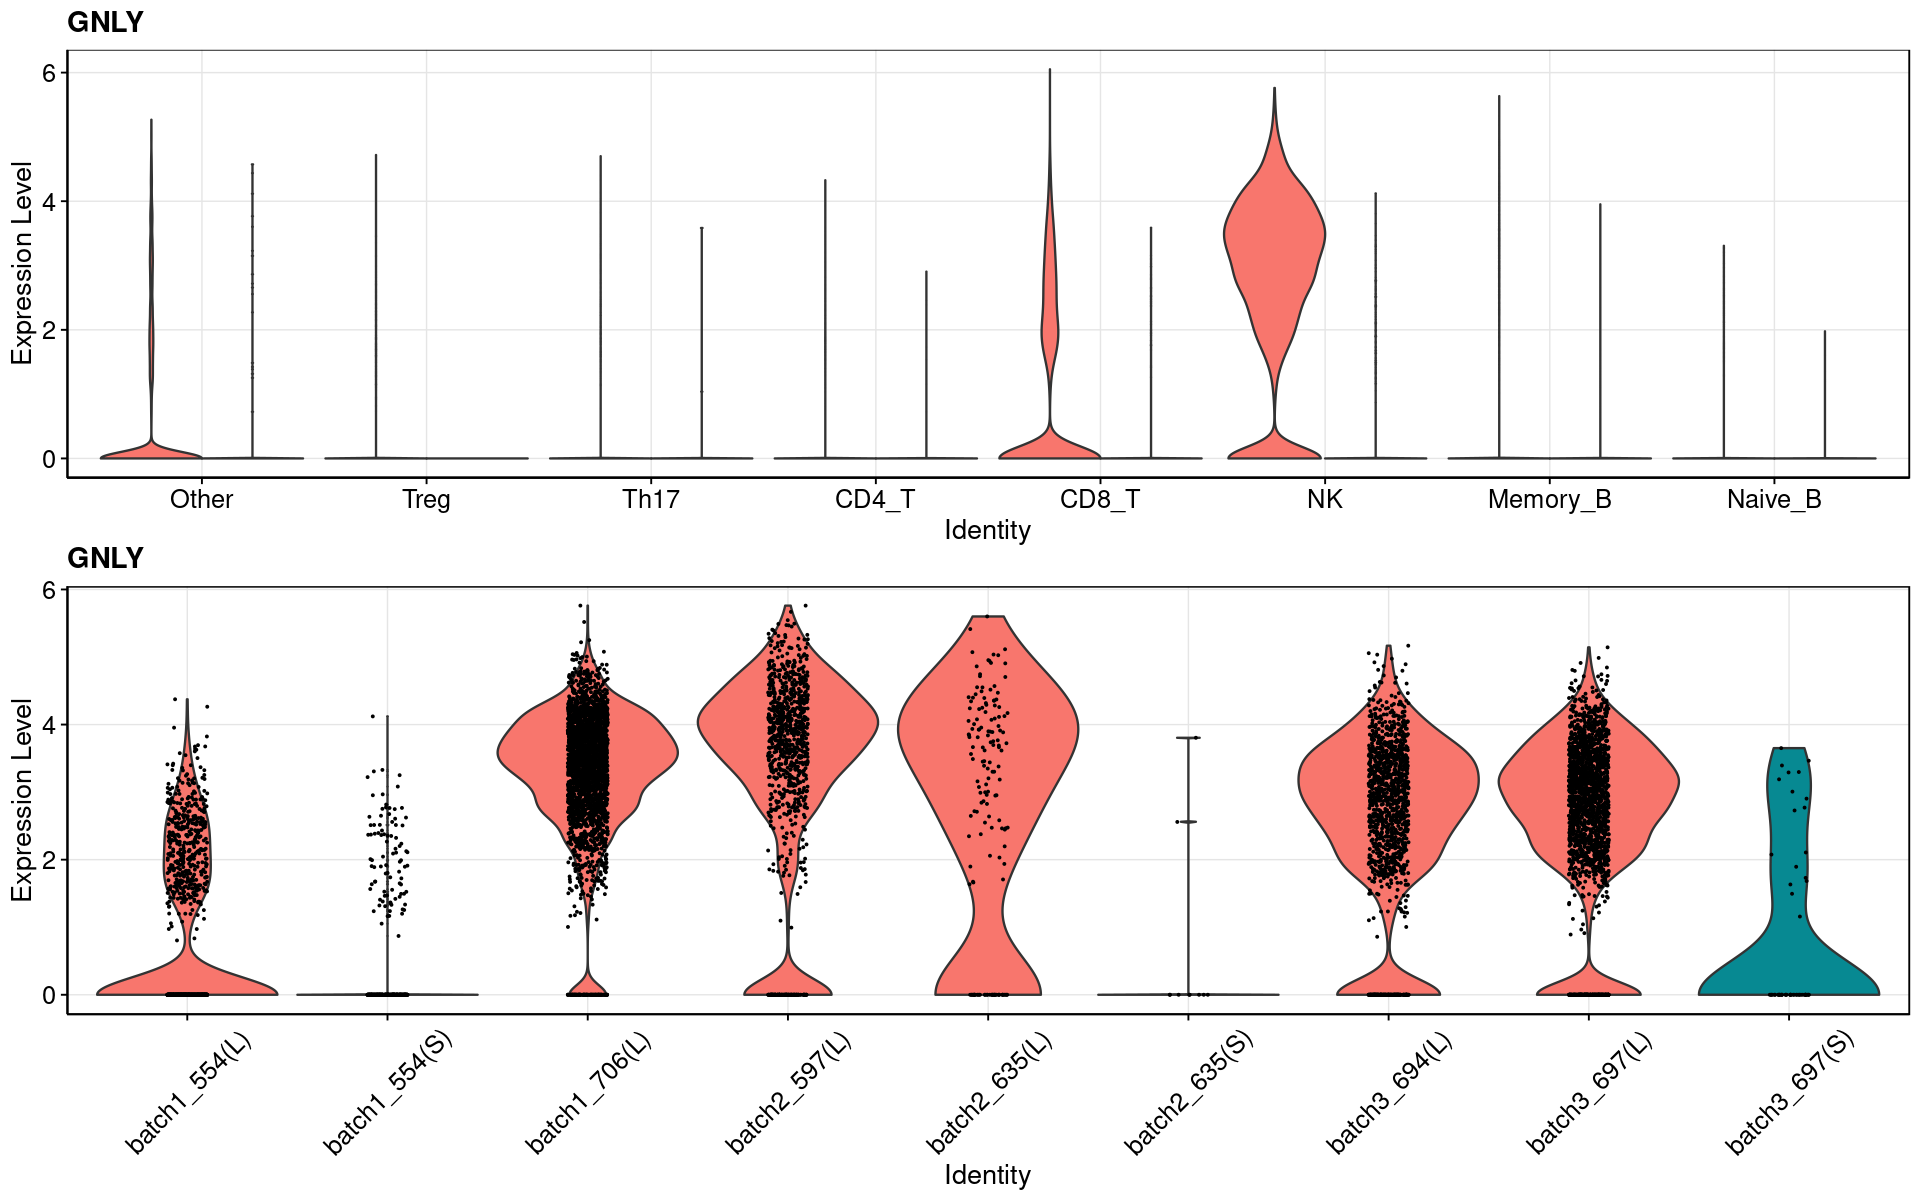

In [57]:
p1/p2

<a id='section5'></a>

## Examine the functions of lung or spleen DE genes 

We performed GO enrichment test for DE genes one cell type at at time separately for each tissue.

In [ ]:
## Prepare inputs for GO enrichment
bkgGenes <- unique(tests$Other$gene)
lung_up <- gginput[gginput$group == "Lung Up-regulated", ]
genesets <- lapply(split(lung_up, lung_up$cluster), function(i) {i$gene})
spleen_up <- gginput[gginput$group == "Spleen Up-regulated", ]
genesets <- lapply(split(spleen_up, spleen_up$cluster), function(i) {i$gene})

In [ ]:
## Bash 
Rscript --vanilla code/run_GO_enrichment.R --geneset lung_up.RDS --bkg genesets.RDS --out lung_upreg
Rscript --vanilla code/run_GO_enrichment.R --geneset spleen_up.RDS --bkg genesets.RDS --out spleen_upreg

In [ ]:
## Visulize GO enrichment outputs
go_list <- readRDS("lung_upreg_GO_enrichment.RDS")
feature = "Biological"
go_tbl <-
  do.call(rbind, go_list) %>%
    filter(k %in% ct_order[1:5])
write.table(go_tbl %>% filter(FDR <= 0.05 & grepl("Biological", database)) %>% dplyr::select(-database), "tables/Enriched_GO_BP_lungUp.txt", quote = F, sep = "\t")
toshow <- 
    unique(
      go_tbl %>% 
        filter(FDR <= 0.05 & grepl(feature, database)) %>%
            group_by(k) %>%
            slice_max(n = 7, order_by = enrichmentRatio) %>%
            pull(description))
p2 <-
ggplot(
    go_tbl %>% 
      filter(grepl(feature, database) & description %in% toshow & 
               FDR <= 0.05) %>%
      mutate(FDR = ifelse(FDR == 0, 10^(-10), FDR),
             Enrichment = enrichmentRatio),
    aes(y = description,
        x = factor(k, levels = ct_order[1:5]),
        size = Enrichment,
        color = -log10(FDR))) + 
    geom_point() + xlab("") + ylab("") + 
     # scale_fill_gradient(
     #   limits = c(0, 4),
     #   oob = squish) +
    theme_pub() + #ggtitle("GO BP enrichment for lung up-regulated genes") 
    theme(axis.text.x = element_text(angle = 45, vjust = 0.5),
          axis.text.y = element_text(),
          legend.position = "bottom")
p2

In [ ]:
go_list <- readRDS("spleen_upreg_GO_enrichment.RDS")
feature = "Biological"
go_tbl <-
  do.call(rbind, go_list) %>%
    filter(k %in% ct_order[1:5])
write.table(go_tbl %>% filter(FDR <= 0.1 & grepl("Biological", database)) %>% dplyr::select(-database), "tables/Enriched_GO_BP_spleenUp.txt", quote = F, sep = "\t")

toshow <- 
    go_tbl %>% 
      filter(FDR <= 0.1 & grepl(feature, database)) %>%
          group_by(k) %>%
          #slice_max(n = 8, order_by = enrichmentRatio) %>%
          pull(description)

ggplot(
    go_tbl %>% 
      filter(grepl(feature, database) & description %in% toshow),
    aes(y = description,
        x = factor(k, levels = ct_order[1:5]),
        size = enrichmentRatio,
        color = -log10(FDR_adj))) + 
    geom_point() + xlab("") + ylab("") + 
     # scale_fill_gradient(
     #   limits = c(0, 4),
     #   oob = squish) +
    theme_pub() + ggtitle("GO BP enrichment for spleen up-regulated genes") 
    #theme(axis.text.x = element_text(angle = 45, vjust = 0.5))